# Week 4 Day 2 ? Probability
## Probability Concepts and Distributions

**Objective:** Explore basic probability, normal distribution, binomial distribution, and the Central Limit Theorem using Python.

Business context: Probability helps analysts estimate risks, understand uncertainty, and support business forecasting.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

np.random.seed(42)
print("Libraries imported successfully")


Libraries imported successfully


## 1. Basic Probability Using a Contingency Table

A contingency table summarizes two categorical variables. We use it to calculate:
- P(A): probability of event A
- P(A and B): joint probability
- P(A given B): conditional probability


In [2]:
# Example: customer purchases by region
table = pd.DataFrame(
    {"Purchased": [30, 20], "Not Purchased": [10, 40]},
    index=["North", "South"]
)

display(table)

total = table.values.sum()
event_a = table.loc["North", "Purchased"]
event_b = table.loc[:, "Purchased"].sum()
intersection = table.loc["North", "Purchased"]

p_a = table.loc["North"].sum() / total
p_b = event_b / total
p_a_and_b = intersection / total
p_a_given_b = intersection / event_b

print(f"P(A = North): {p_a:.2f}")
print(f"P(B = Purchased): {p_b:.2f}")
print(f"P(A and B): {p_a_and_b:.2f}")
print(f"P(A given B): {p_a_given_b:.2f}")


,Purchased,Not Purchased
North,30,10
South,20,40


P(A = North): 0.40
P(B = Purchased): 0.50
P(A and B): 0.30
P(A given B): 0.60


## 2. Normal Distribution and the 68-95-99.7 Rule

A normal distribution is a bell-shaped distribution.
- About 68% of values fall within 1 standard deviation of the mean.
- About 95% fall within 2 standard deviations.
- About 99.7% fall within 3 standard deviations.


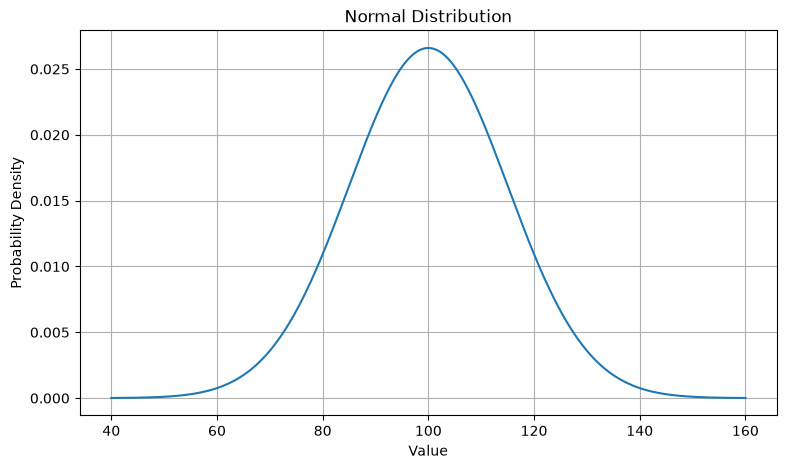

Within 1 standard deviation(s): 0.00%
Within 2 standard deviation(s): 0.00%
Within 3 standard deviation(s): 0.00%


In [3]:
mean = 100
std = 15
x = np.linspace(mean - 4*std, mean + 4*std, 500)
y = norm.pdf(x, mean, std)

plt.figure(figsize=(9, 5))
plt.plot(x, y)
plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Probability Density")
plt.grid(True)
plt.show()

for k in [1, 2, 3]:
    percentage = (norm.cdf(mean + k*std) - norm.cdf(mean - k*std)) * 100
    print(f"Within {k} standard deviation(s): {percentage:.2f}%")


## 3. Binomial Distribution Simulation

A binomial distribution models the number of successes in a fixed number of independent trials, each with the same success probability.


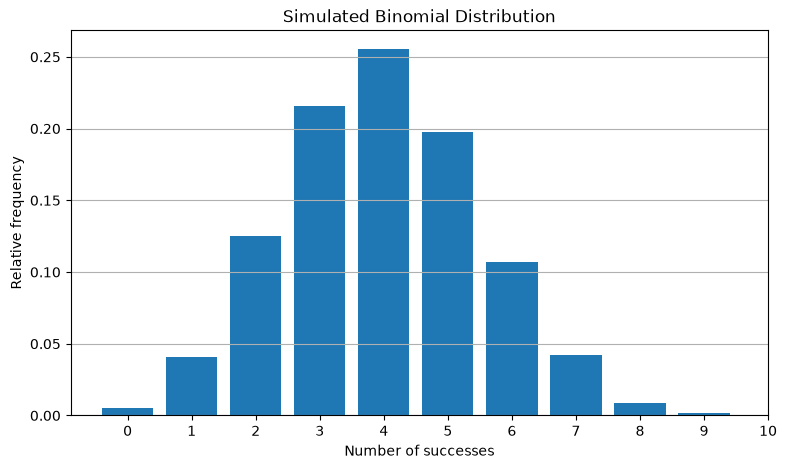

Simulated average number of successes: 3.97
Theoretical average (n ? p): 4.0


In [4]:
n = 10       # number of trials
p = 0.4      # probability of success
simulations = 10000

results = np.random.binomial(n=n, p=p, size=simulations)
counts = pd.Series(results).value_counts(normalize=True).sort_index()

plt.figure(figsize=(9, 5))
plt.bar(counts.index, counts.values)
plt.title("Simulated Binomial Distribution")
plt.xlabel("Number of successes")
plt.ylabel("Relative frequency")
plt.xticks(range(n + 1))
plt.grid(axis="y")
plt.show()

print("Simulated average number of successes:", round(results.mean(), 2))
print("Theoretical average (n ? p):", n * p)


## 4. Central Limit Theorem (CLT)

The Central Limit Theorem says that the distribution of sample means becomes approximately normal as the sample size increases, even when the original population is not normally distributed.

Business example: An analyst repeatedly samples customer order values. The average order value from each sample tends to form a normal distribution when sample sizes are sufficiently large.


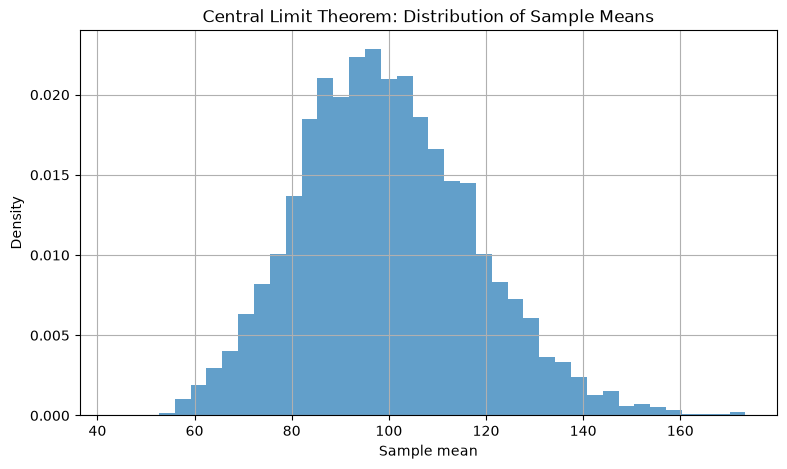

Population mean: 99.77
Mean of sample means: 99.61
Standard error (theoretical): 18.14
Standard deviation of sample means: 18.13


In [5]:
# Use a skewed population of order values
population = np.random.exponential(scale=100, size=100000)

sample_size = 30
number_of_samples = 5000
sample_means = [
    np.mean(np.random.choice(population, size=sample_size, replace=True))
    for _ in range(number_of_samples)
]

plt.figure(figsize=(9, 5))
plt.hist(sample_means, bins=40, density=True, alpha=0.7)
plt.title("Central Limit Theorem: Distribution of Sample Means")
plt.xlabel("Sample mean")
plt.ylabel("Density")
plt.grid(True)
plt.show()

print("Population mean:", round(population.mean(), 2))
print("Mean of sample means:", round(np.mean(sample_means), 2))
print("Standard error (theoretical):", round(population.std() / np.sqrt(sample_size), 2))
print("Standard deviation of sample means:", round(np.std(sample_means), 2))


## Conclusion

- Probability measures how likely an event is.
- A contingency table helps calculate joint and conditional probabilities.
- The normal distribution follows the 68-95-99.7 rule.
- The binomial distribution counts successes in repeated trials.
- The Central Limit Theorem explains why sample means become approximately normal.

## Viva Notes

1. **Conditional probability:** Probability of an event when another event is already known to have occurred.
2. **Central Limit Theorem:** The distribution of sample means approaches a normal distribution as sample size increases.
3. **Discrete distribution:** Takes countable values, such as number of purchases.
4. **Continuous distribution:** Takes values over a range, such as order amount or delivery time.
